<center><h1>Sun_Yizhi_HW6</h1></center>

Name: Yizhi Sun
<br>
Github Username: yizhisun515
<br>
USC ID: 6129500198

## 1. Tree-Based Methods

Import packages

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score,
    accuracy_score
)
from sklearn.model_selection import StratifiedKFold, cross_val_score

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

### (a) Download the APS Failure data

In [2]:
train_path = Path("../data/aps_failure_training_set.csv")
test_path = Path("../data/aps_failure_test_set.csv")

# Skip the 20-line metadata header in the original files
aps_train = pd.read_csv(
    train_path,
    skiprows=20,
    na_values=["na"]
)

aps_test = pd.read_csv(
    test_path,
    skiprows=20,
    na_values=["na"]
)

print("Training data shape:", aps_train.shape)
print("Test data shape:", aps_test.shape)

print("\nTraining data preview:")
display(aps_train.head())

print("\nTest data preview:")
display(aps_test.head())

print("\nMissing values in training data:")
print(aps_train.isna().sum().sum())

Training data shape: (60000, 171)
Test data shape: (16000, 171)

Training data preview:


,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,ag_003,ag_004,ag_005,ag_006,ag_007,...,eb_000,ec_00,ed_000,ee_000,ee_001,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,0.0,37250.0,1432864.0,3664156.0,1007684.0,...,2801180.0,2445.80,2712.0,965866.0,1706908.0,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,0.0,18254.0,653294.0,1720800.0,516724.0,...,3477820.0,2211.76,2334.0,664504.0,824154.0,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,0.0,1648.0,370592.0,1883374.0,292936.0,...,1040120.0,1018.64,1020.0,262032.0,453378.0,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,318.0,2212.0,3232.0,1872.0,0.0,...,0.0,1.08,54.0,5670.0,1566.0,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,0.0,43752.0,1966618.0,1800340.0,131646.0,...,21173050.0,1116.06,1176.0,404740.0,904230.0,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0



Test data preview:


,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,ag_003,ag_004,ag_005,ag_006,ag_007,...,eb_000,ec_00,ed_000,ee_000,ee_001,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,60,0.0,20.0,12.0,0.0,0.0,0.0,0.0,0.0,2682.0,4736.0,3862.0,1846.0,0.0,...,0.0,465.50,90.0,7502.0,3156.0,1098.0,138.0,412.0,654.0,78.0,88.0,0.0,0.0,0.0,0.0
1,neg,82,0.0,68.0,40.0,0.0,0.0,0.0,0.0,0.0,0.0,748.0,12594.0,3636.0,0.0,...,0.0,2.86,102.0,10040.0,3310.0,1068.0,276.0,1620.0,116.0,86.0,462.0,0.0,0.0,0.0,0.0
2,neg,66002,2.0,212.0,112.0,0.0,0.0,0.0,0.0,0.0,199486.0,1358536.0,1952422.0,452706.0,25130.0,...,26002880.0,2057.84,2158.0,396312.0,538136.0,495076.0,380368.0,440134.0,269556.0,1315022.0,153680.0,516.0,0.0,0.0,0.0
3,neg,59816,NaN,1010.0,936.0,0.0,0.0,0.0,0.0,0.0,0.0,123922.0,984314.0,1680050.0,1135268.0,...,1179900.0,1541.32,1678.0,659550.0,691580.0,540820.0,243270.0,483302.0,485332.0,431376.0,210074.0,281662.0,3232.0,0.0,0.0
4,neg,1814,NaN,156.0,140.0,0.0,0.0,0.0,0.0,0.0,0.0,72.0,17926.0,82834.0,3114.0,...,813740.0,113.86,52.0,10216.0,9958.0,7646.0,4144.0,18466.0,49782.0,3176.0,482.0,76.0,0.0,0.0,0.0



Missing values in training data:
850015


### (b) Data Preparation

#### (i) Research what types of techniques are usually used

Common approaches for handling missing data include deletion, mean or median imputation, k-nearest neighbors (KNN) imputation, and model-based imputation. Deletion may lead to substantial information loss when missingness is widespread. Mean and median imputation replace missing values with a feature's mean or median, while KNN and model-based methods estimate missing values using information from other observations or features.

For this dataset, median imputation is selected because it is computationally efficient and robust to extreme values in numerical features. The imputer is fitted only on the training data and subsequently applied to both the training and test sets, preventing information leakage from the test data.

In [3]:
X_train = aps_train.drop(columns=["class"])
X_test = aps_test.drop(columns=["class"])

y_train = aps_train["class"].map({"neg": 0, "pos": 1})
y_test = aps_test["class"].map({"neg": 0, "pos": 1})

imputer = SimpleImputer(strategy="median")

X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("Remaining missing values in training set:",
      X_train_imputed.isna().sum().sum())

print("Remaining missing values in test set:",
      X_test_imputed.isna().sum().sum())

print("Imputed training shape:", X_train_imputed.shape)
print("Imputed test shape:", X_test_imputed.shape)

Remaining missing values in training set: 0
Remaining missing values in test set: 0
Imputed training shape: (60000, 170)
Imputed test shape: (16000, 170)


#### (ii) Calculate the coefficient of variation

In [4]:
feature_means = X_train_imputed.mean()
feature_stds = X_train_imputed.std(ddof=1)

cv_values = feature_stds / feature_means.replace(0, np.nan)

cv_df = pd.DataFrame({
    "Mean": feature_means,
    "Standard Deviation": feature_stds,
    "Coefficient of Variation": cv_values
})

cv_df = cv_df.sort_values(
    by="Coefficient of Variation",
    ascending=False
)

print("Number of features:", len(cv_df))
print("Features with undefined CV:", cv_df["Coefficient of Variation"].isna().sum())

display(cv_df)

Number of features: 170
Features with undefined CV: 0


,Mean,Standard Deviation,Coefficient of Variation
cf_000,1.431075e+05,3.504525e+07,244.887517
co_000,1.433300e+05,3.504525e+07,244.507385
ad_000,1.434383e+05,3.504525e+07,244.322816
cs_009,7.705097e+02,1.833278e+05,237.930554
dh_000,4.392641e+03,5.412441e+05,123.216097
...,...,...,...
bo_000,3.258947e+05,2.582334e+05,0.792383
bp_000,3.420739e+05,2.577156e+05,0.753392
bq_000,3.573117e+05,2.567407e+05,0.718534
br_000,3.713041e+05,2.558701e+05,0.689112


The coefficient of variation (CV) was calculated for all 170 numerical features using the sample standard deviation divided by the sample mean after median imputation. All 170 features had defined CV values.

The highest CV values were observed for cf_000 (244.89), co_000 (244.51), and ad_000 (244.32), indicating substantial variability relative to their means. In contrast, cd_000 had a CV of 0, indicating no variation across observations.

Although a high CV may reflect skewed distributions or extreme values, it does not necessarily indicate strong predictive importance or statistical significance. Therefore, the features with the highest CV will be further examined through scatter plots and box plots.

#### (iii) Plot a correlation matrix

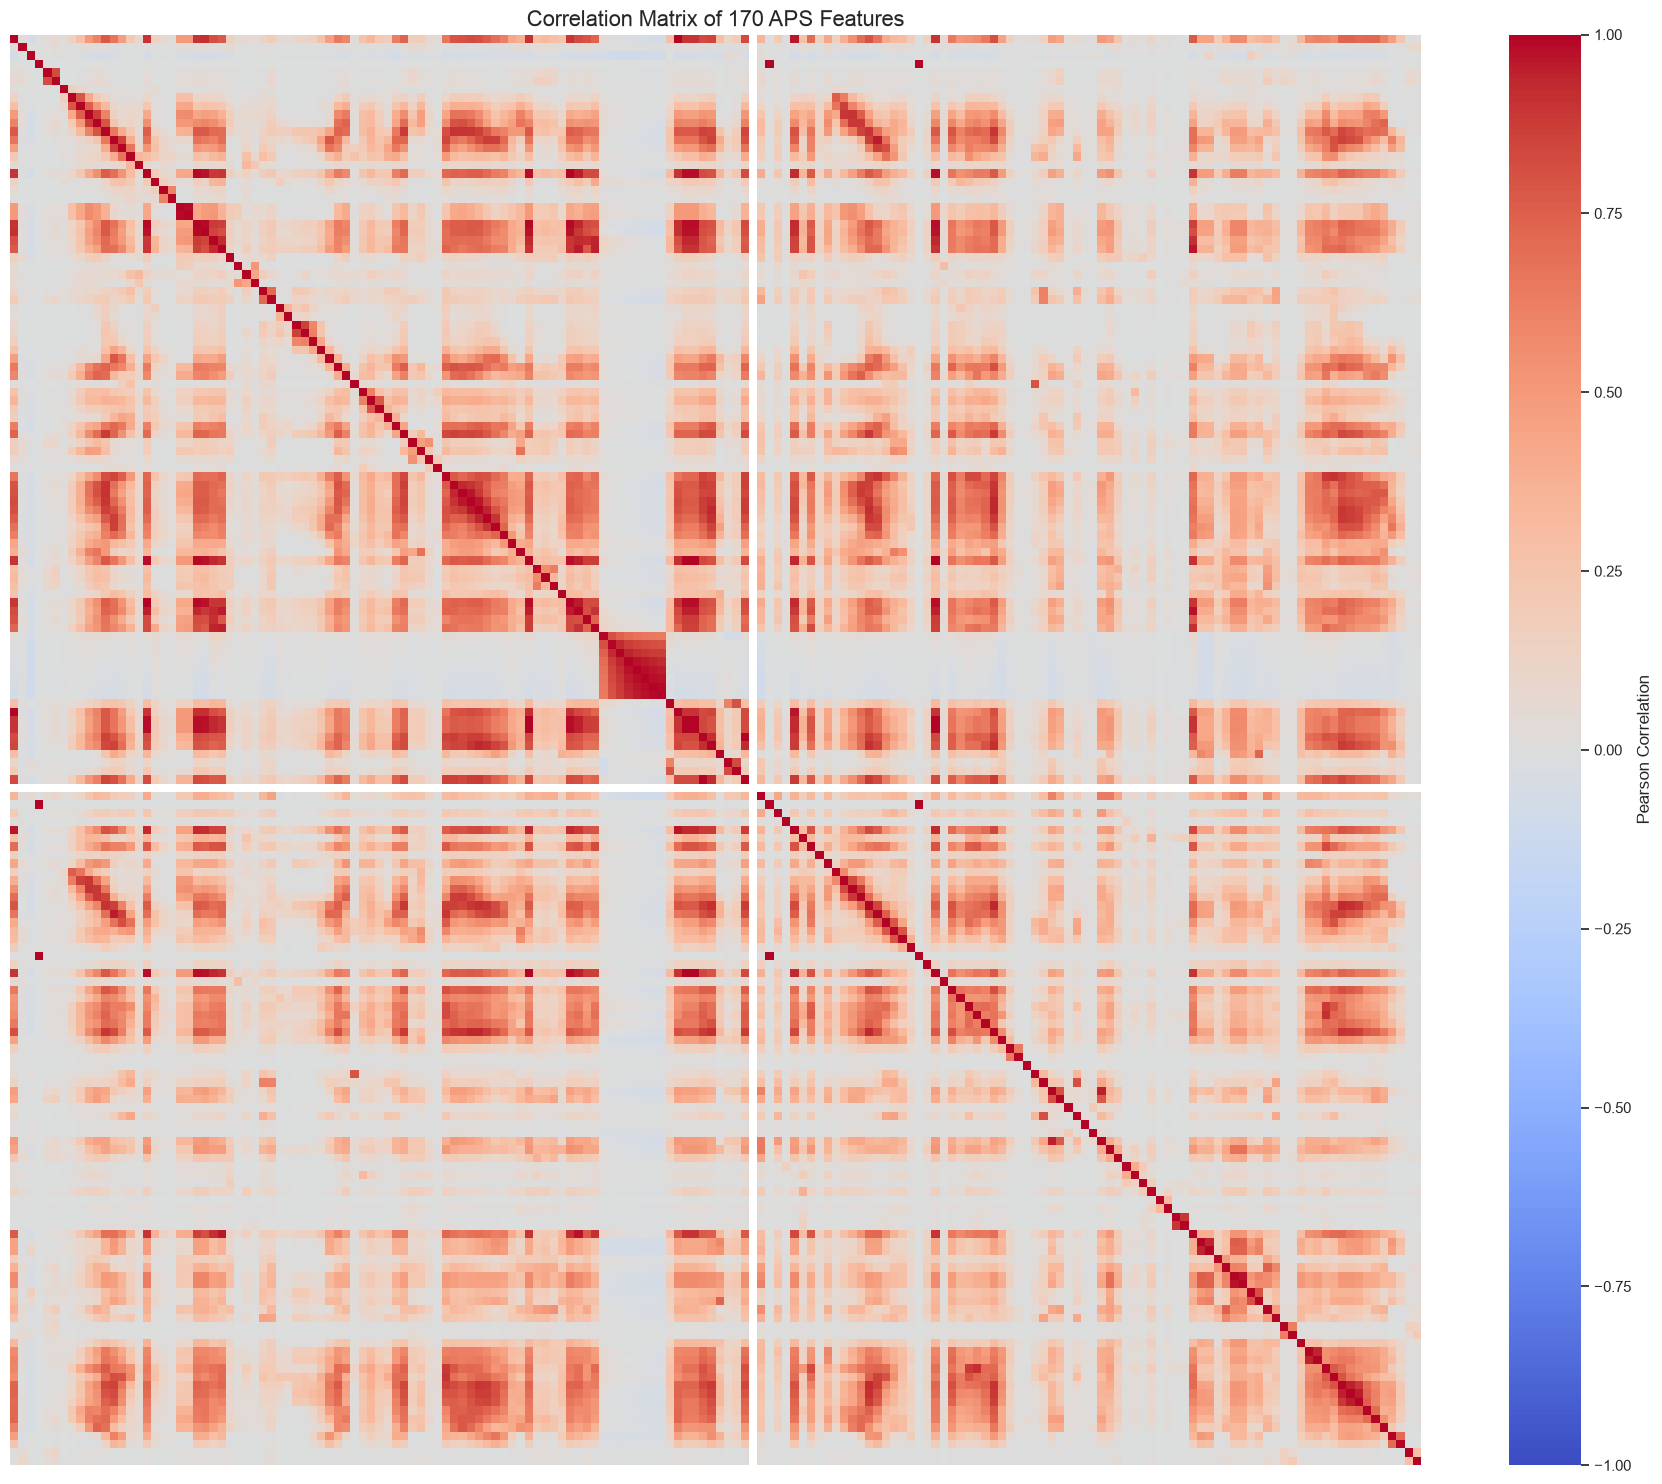

In [5]:
corr_matrix = X_train_imputed.corr()

plt.figure(figsize=(18, 15))

sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    xticklabels=False,
    yticklabels=False,
    cbar_kws={"label": "Pearson Correlation"}
)

plt.title("Correlation Matrix of 170 APS Features", fontsize=16)
plt.tight_layout()
plt.show()

The correlation heatmap shows several blocks of strongly positively correlated features, suggesting potential redundancy among groups of predictors. Strong negative correlations are comparatively uncommon, while many feature pairs show weak linear relationships. Some horizontal and vertical bands may reflect features with undefined or near-zero correlations. Overall, the dataset exhibits substantial correlation structure, but correlation alone does not establish feature importance for predicting APS failure.

#### (iv) Make scatter plots and box plots

Number of selected features: 13
Selected features: ['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000']


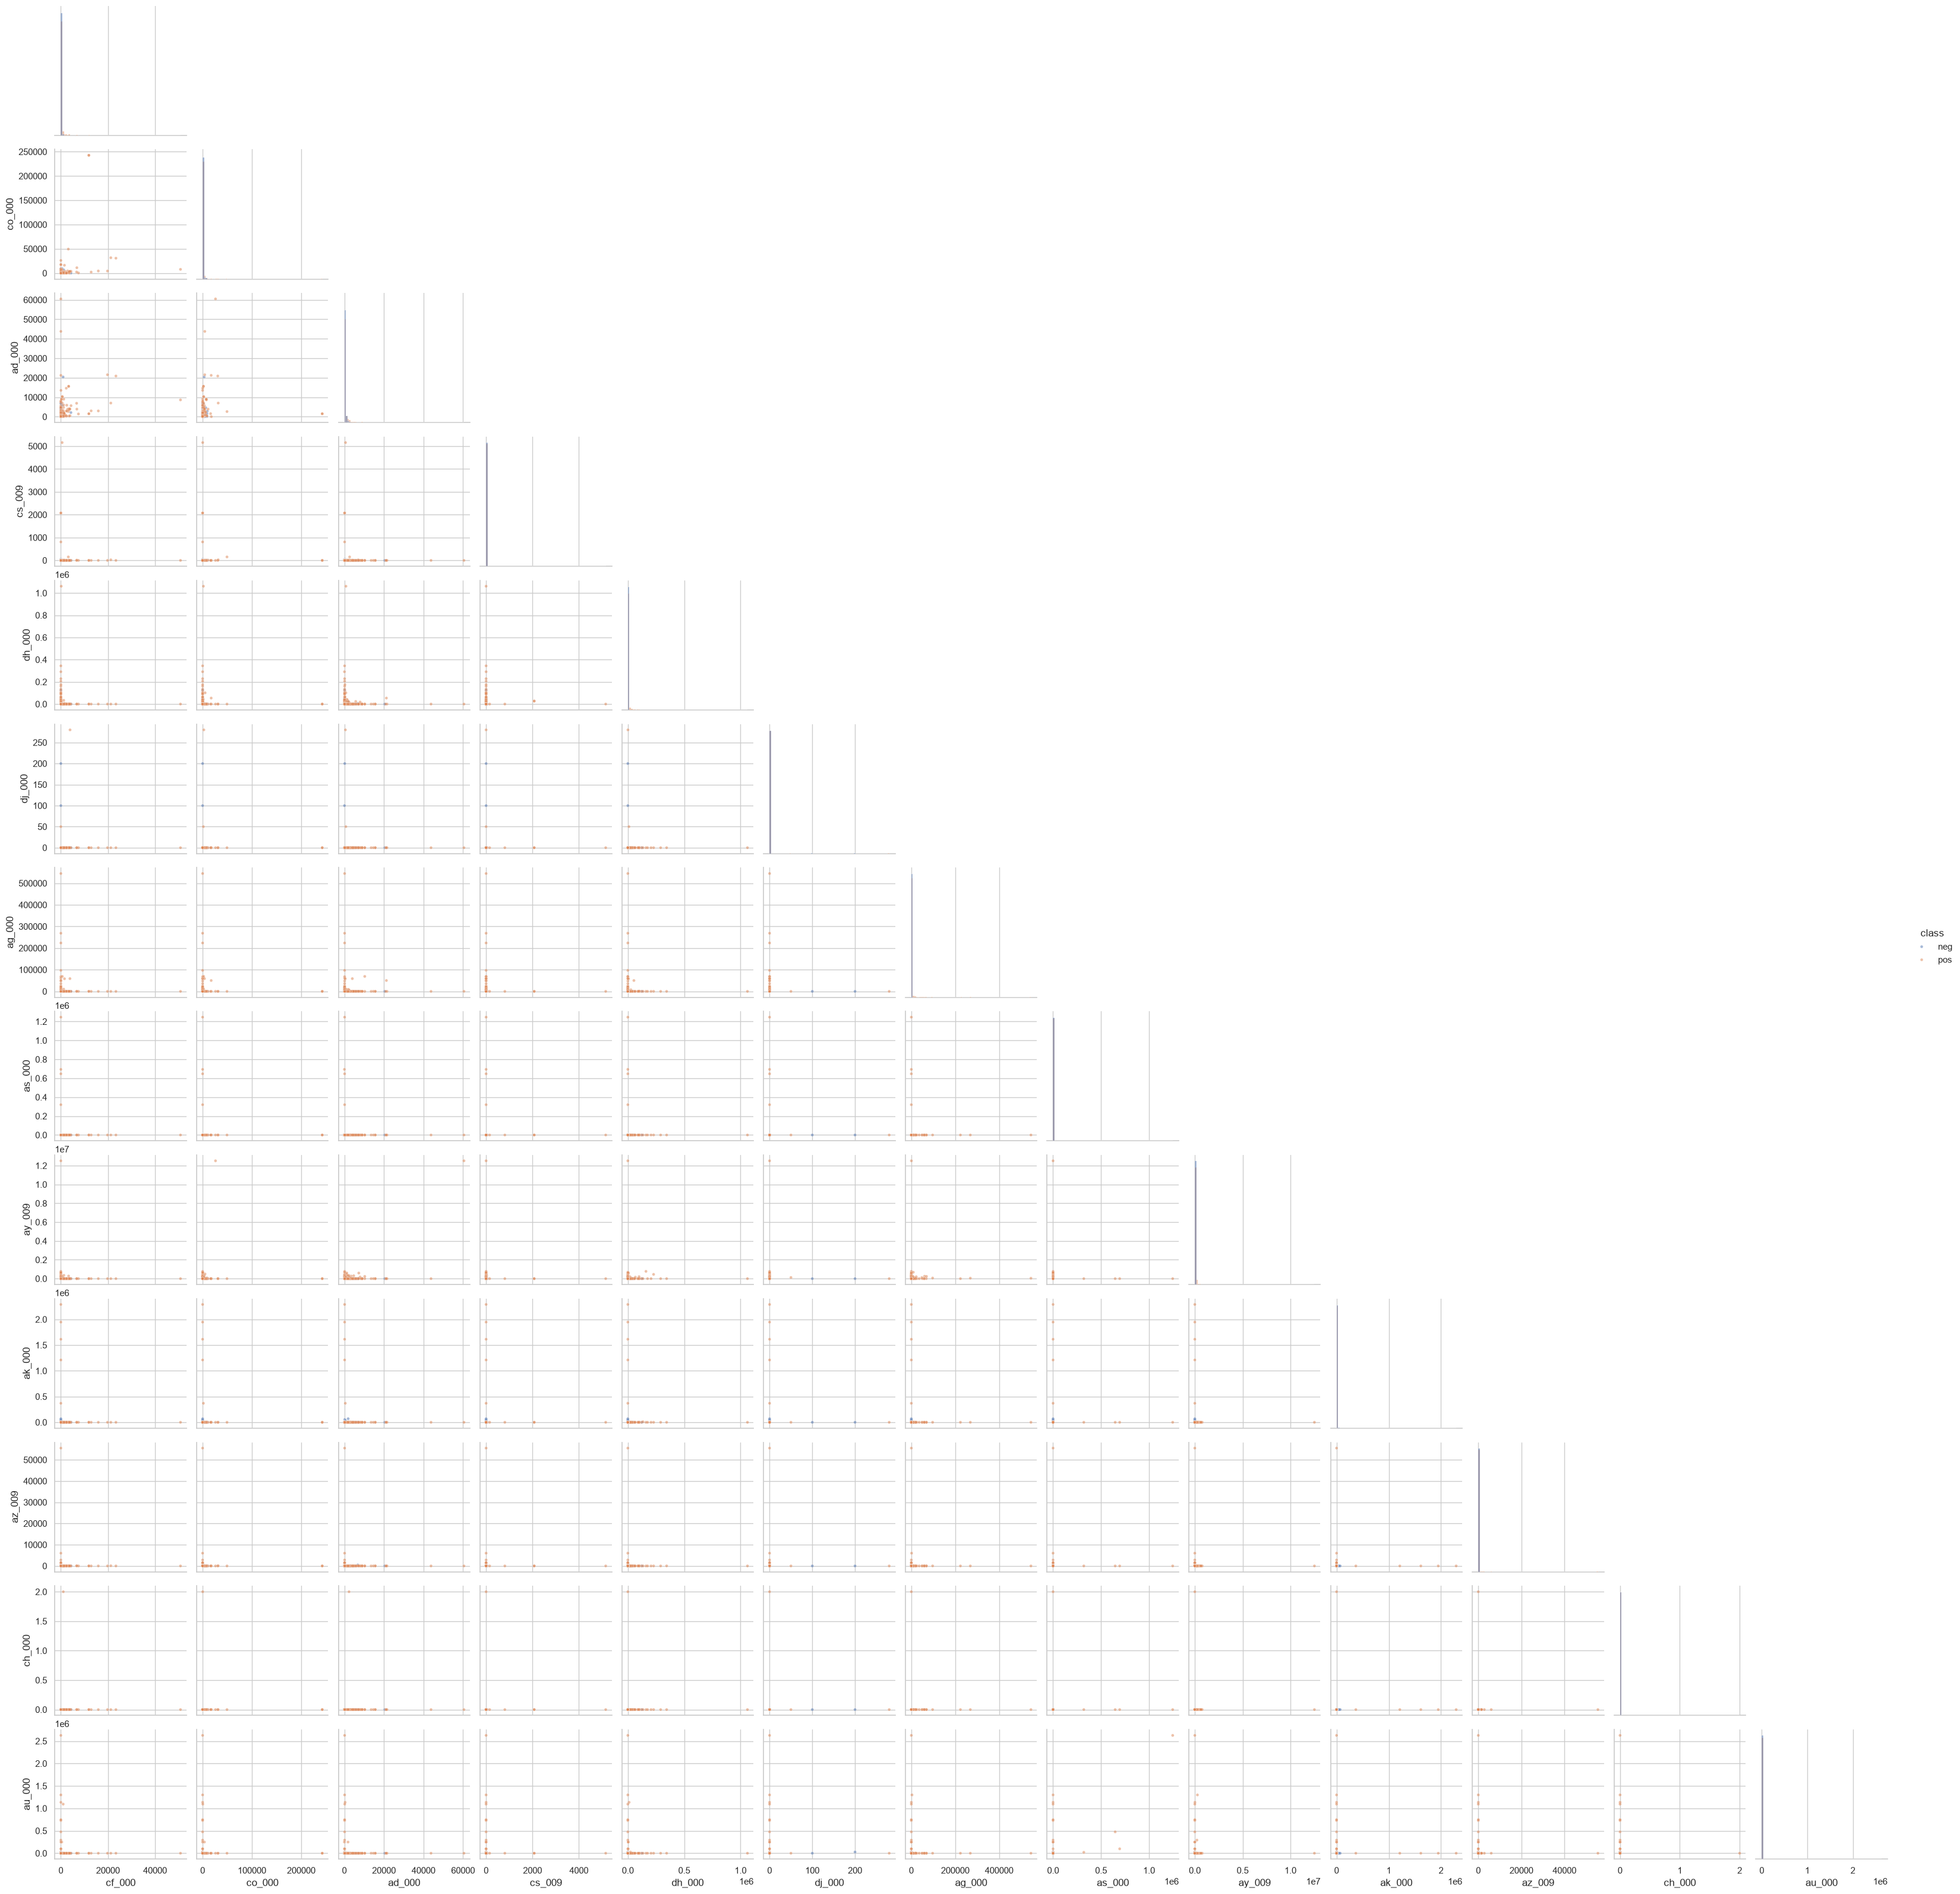

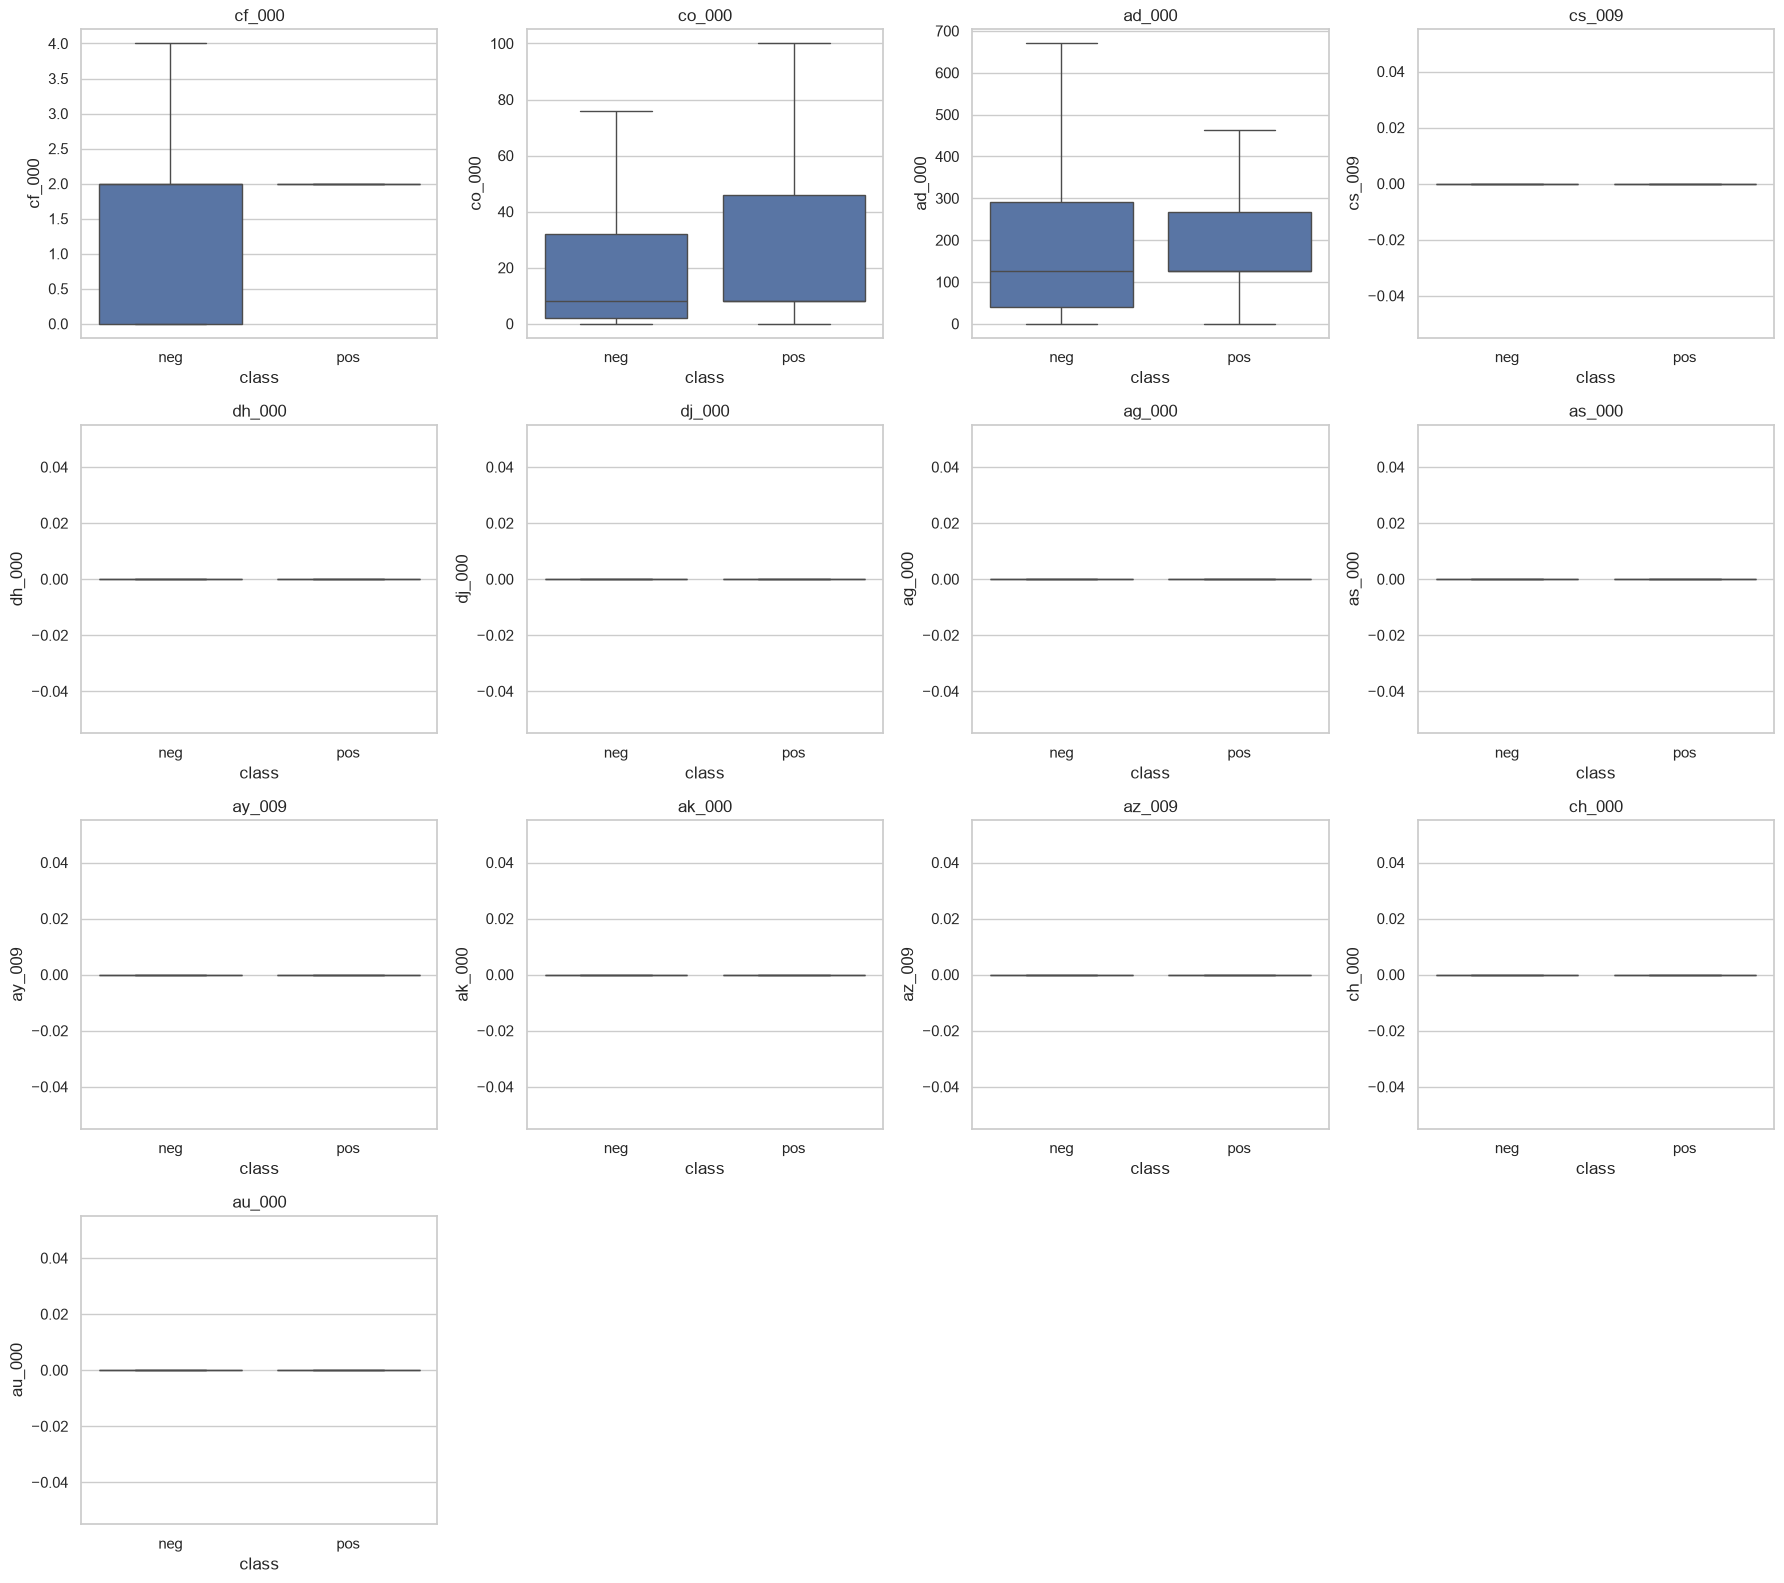

In [6]:
n_features = int(np.sqrt(X_train_imputed.shape[1]))

top_features = (
    cv_df["Coefficient of Variation"]
    .dropna()
    .nlargest(n_features)
    .index
    .tolist()
)

print("Number of selected features:", len(top_features))
print("Selected features:", top_features)

plot_df = X_train_imputed[top_features].copy()
plot_df["class"] = y_train.map({0: "neg", 1: "pos"})

plot_sample = pd.concat([
    plot_df[plot_df["class"] == "neg"].sample(
        n=750, random_state=RANDOM_STATE
    ),
    plot_df[plot_df["class"] == "pos"].sample(
        n=750, random_state=RANDOM_STATE
    )
])

sns.pairplot(
    plot_sample,
    vars=top_features,
    hue="class",
    corner=True,
    plot_kws={"alpha": 0.5, "s": 12},
    diag_kind="hist"
)

plt.show()

fig, axes = plt.subplots(4, 4, figsize=(18, 16))
axes = axes.flatten()

for i, feature in enumerate(top_features):
    sns.boxplot(
        data=plot_df,
        x="class",
        y=feature,
        order=["neg", "pos"],
        ax=axes[i],
        showfliers=False
    )
    axes[i].set_title(feature)

for j in range(len(top_features), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

The 13 features with the highest coefficients of variation were selected for visualization. For the scatter plots, 750 observations were randomly sampled from each class to improve visibility, while the box plots used the full training dataset.

The scatter plots show that many observations are concentrated near zero, with a small number of extreme values. Similarly, several box plots appear nearly flat due to highly concentrated distributions. Features such as co_000 and ad_000 show some visible differences between the positive and negative classes, although substantial overlap remains.

However, **statistical significance cannot be determined from scatter plots alone**. A high coefficient of variation indicates substantial relative variability rather than predictive importance. Extreme values, overlapping class distributions, and severe class imbalance further complicate interpretation. Formal statistical tests or model-based evaluations are required to assess whether these features are significantly associated with APS failure.

#### (v) Is this data set imbalanced?

In [7]:
train_counts = y_train.value_counts().sort_index()
test_counts = y_test.value_counts().sort_index()

class_distribution = pd.DataFrame({
    "Training Count": train_counts,
    "Test Count": test_counts
})

class_distribution.index = ["Negative", "Positive"]

class_distribution["Training Percentage"] = (
    class_distribution["Training Count"] / len(y_train) * 100
)

class_distribution["Test Percentage"] = (
    class_distribution["Test Count"] / len(y_test) * 100
)

display(class_distribution.round(2))

,Training Count,Test Count,Training Percentage,Test Percentage
Negative,59000,15625,98.33,97.66
Positive,1000,375,1.67,2.34


The APS Failure dataset is severely imbalanced. The training set contains 59,000 negative observations (98.33%) and 1,000 positive observations (1.67%), while the test set contains 15,625 negative observations (97.66%) and 375 positive observations (2.34%).

The large difference in class frequencies may cause classification models to favor the majority class. Therefore, accuracy alone may be misleading, and additional metrics such as the confusion matrix, ROC curve, and AUC are needed to evaluate classification performance.

### (c) Train a random forest

,Dataset,AUC,Misclassification Rate
0,Training,1.0000,0.0000
1,Test,0.9944,0.0073


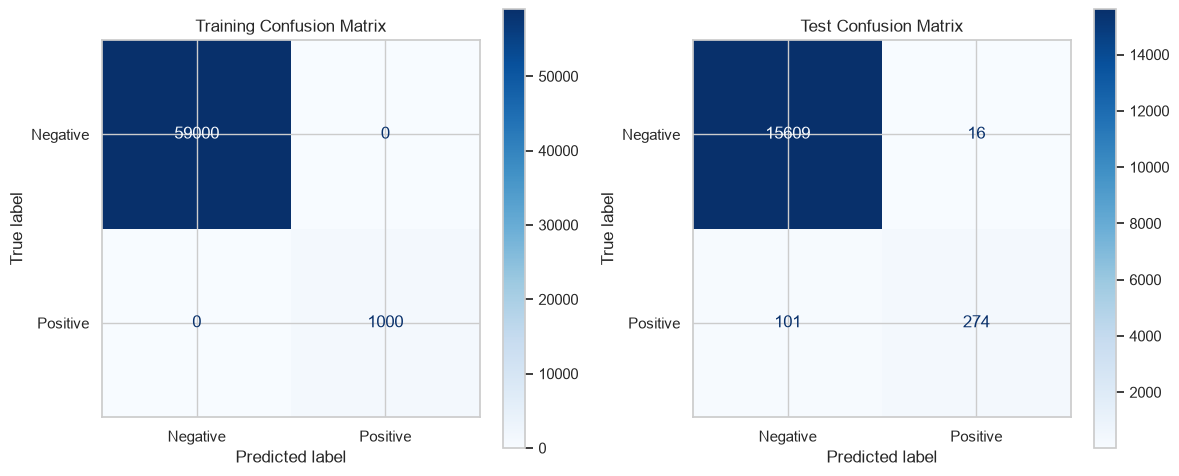

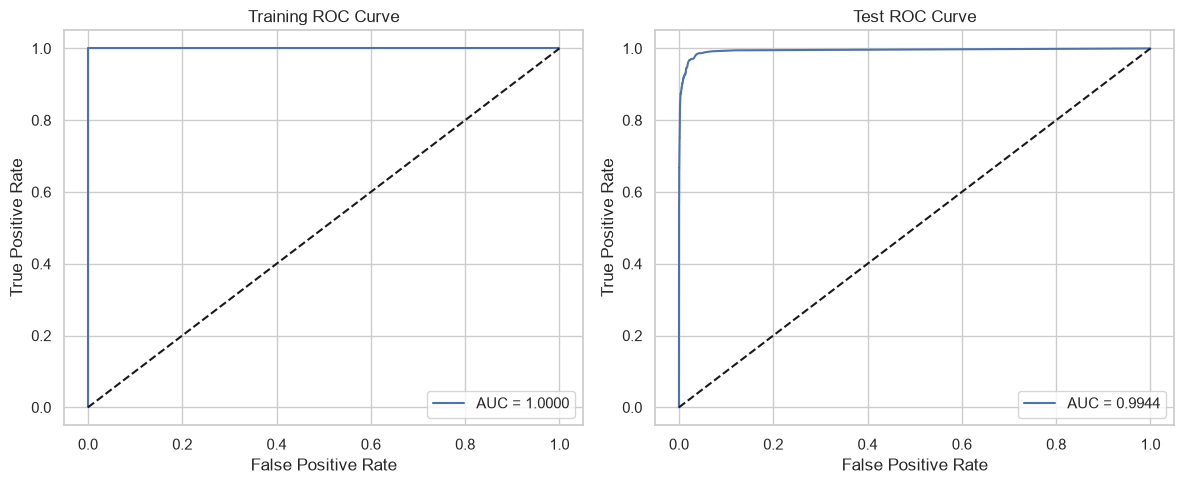

OOB Error: 0.0058
Test Error: 0.0073
Difference (OOB - Test): -0.0015


In [8]:
rf = RandomForestClassifier(
    n_estimators=200,
    class_weight=None,
    oob_score=True,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf.fit(X_train_imputed, y_train)

rf_train_pred = rf.predict(X_train_imputed)
rf_test_pred = rf.predict(X_test_imputed)

rf_train_prob = rf.predict_proba(X_train_imputed)[:, 1]
rf_test_prob = rf.predict_proba(X_test_imputed)[:, 1]

rf_results = pd.DataFrame({
    "Dataset": ["Training", "Test"],
    "AUC": [
        roc_auc_score(y_train, rf_train_prob),
        roc_auc_score(y_test, rf_test_prob)
    ],
    "Misclassification Rate": [
        1 - accuracy_score(y_train, rf_train_pred),
        1 - accuracy_score(y_test, rf_test_pred)
    ]
})

display(rf_results.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_train,
    rf_train_pred,
    display_labels=["Negative", "Positive"],
    cmap="Blues",
    ax=axes[0]
)
axes[0].set_title("Training Confusion Matrix")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_test_pred,
    display_labels=["Negative", "Positive"],
    cmap="Blues",
    ax=axes[1]
)
axes[1].set_title("Test Confusion Matrix")

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, y_true, y_prob, title in [
    (axes[0], y_train, rf_train_prob, "Training ROC Curve"),
    (axes[1], y_test, rf_test_prob, "Test ROC Curve")
]:
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    auc = roc_auc_score(y_true, y_prob)

    ax.plot(fpr, tpr, label=f"AUC = {auc:.4f}")
    ax.plot([0, 1], [0, 1], "k--")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title(title)
    ax.legend()

plt.tight_layout()
plt.show()

rf_oob_error = 1 - rf.oob_score_
rf_test_error = 1 - accuracy_score(y_test, rf_test_pred)

print(f"OOB Error: {rf_oob_error:.4f}")
print(f"Test Error: {rf_test_error:.4f}")
print(f"Difference (OOB - Test): {rf_oob_error - rf_test_error:.4f}")

A Random Forest classifier with 200 trees was trained using all 170 features without compensating for class imbalance. Out-of-bag (OOB) evaluation was enabled to estimate generalization error.

The model achieved a training AUC of 1.0000 with zero misclassification error. On the test set, the AUC was 0.9944 and the misclassification rate was 0.0073. The test confusion matrix showed 15,609 true negatives, 16 false positives, 101 false negatives, and 274 true positives.

Despite the high AUC and low overall error, the model failed to identify 101 of the 375 positive test observations, corresponding to a positive-class recall of approximately 73.07%. This suggests that the model may favor the majority negative class, making the overall misclassification rate insufficient for evaluating minority-class performance.

The OOB error estimate was 0.0058, compared with a test error of 0.0073. The difference of approximately 0.0015 indicates that the OOB estimate is reasonably close to the observed test error, although it slightly underestimates it. The perfect training performance and lower test performance also suggest some degree of overfitting.

These results motivate the use of class imbalance compensation in the following analysis.

### (d) Research class imbalance in random forest

,Dataset,AUC,Misclassification Rate
0,Training,1.0000,0.0000
1,Test,0.9918,0.0112


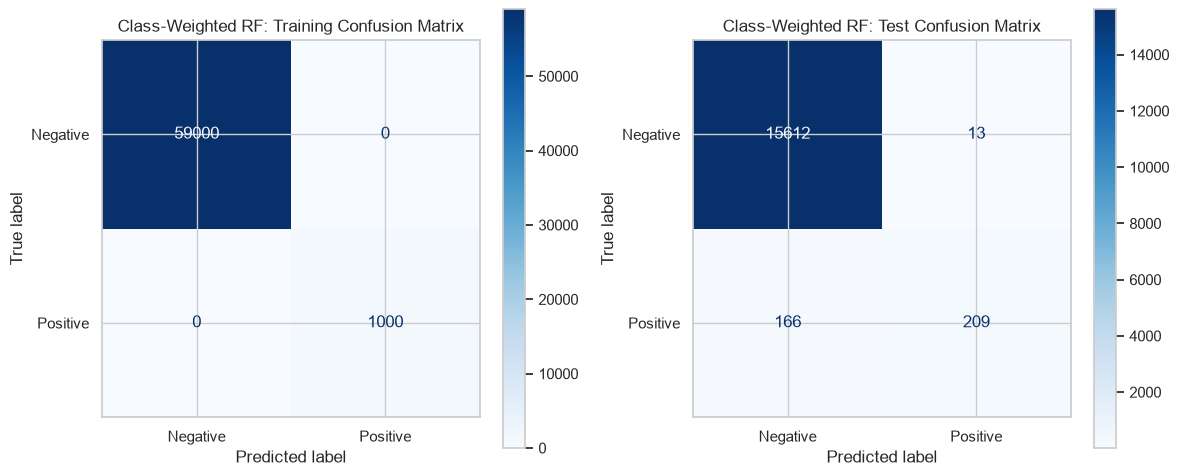

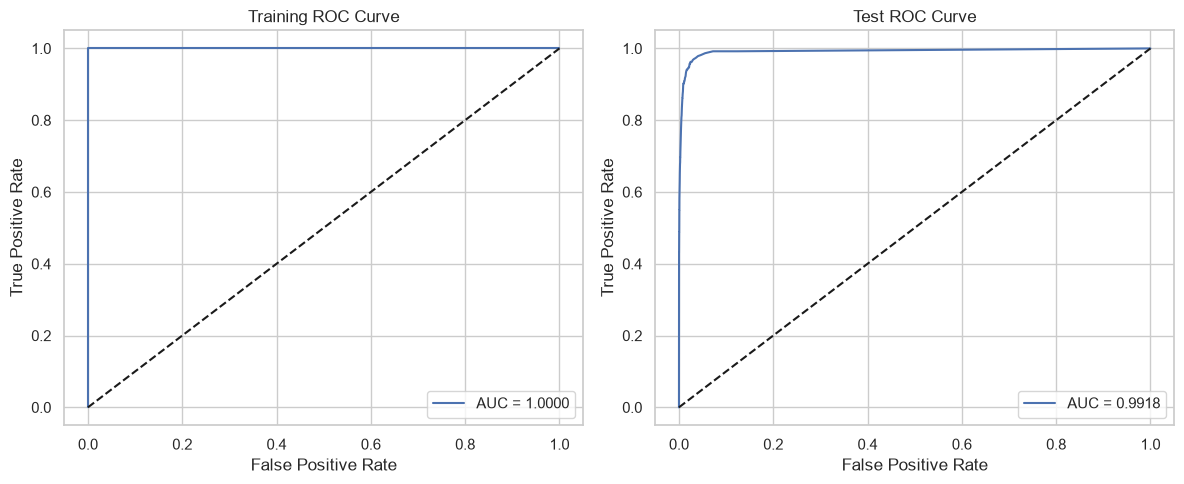

OOB Error: 0.0078
Test Error: 0.0112
Difference (OOB - Test): -0.0034
Observations without valid OOB predictions: 0


Missing OOB Prediction,False
Actual Class,
0,59000
1,1000


In [9]:
rf_balanced = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced_subsample",
    bootstrap=True,
    oob_score=True,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

rf_balanced.fit(X_train_imputed, y_train)

rf_bal_train_pred = rf_balanced.predict(X_train_imputed)
rf_bal_test_pred = rf_balanced.predict(X_test_imputed)

rf_bal_train_prob = rf_balanced.predict_proba(X_train_imputed)[:, 1]
rf_bal_test_prob = rf_balanced.predict_proba(X_test_imputed)[:, 1]

rf_bal_results = pd.DataFrame({
    "Dataset": ["Training", "Test"],
    "AUC": [
        roc_auc_score(y_train, rf_bal_train_prob),
        roc_auc_score(y_test, rf_bal_test_prob)
    ],
    "Misclassification Rate": [
        1 - accuracy_score(y_train, rf_bal_train_pred),
        1 - accuracy_score(y_test, rf_bal_test_pred)
    ]
})

display(rf_bal_results.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_train,
    rf_bal_train_pred,
    display_labels=["Negative", "Positive"],
    cmap="Blues",
    ax=axes[0]
)
axes[0].set_title("Class-Weighted RF: Training Confusion Matrix")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_bal_test_pred,
    display_labels=["Negative", "Positive"],
    cmap="Blues",
    ax=axes[1]
)
axes[1].set_title("Class-Weighted RF: Test Confusion Matrix")

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, y_true, y_prob, title in [
    (axes[0], y_train, rf_bal_train_prob, "Training ROC Curve"),
    (axes[1], y_test, rf_bal_test_prob, "Test ROC Curve")
]:
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    auc_value = roc_auc_score(y_true, y_prob)

    ax.plot(fpr, tpr, label=f"AUC = {auc_value:.4f}")
    ax.plot([0, 1], [0, 1], "k--")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title(title)
    ax.legend()

plt.tight_layout()
plt.show()

rf_bal_oob_error = 1 - rf_balanced.oob_score_
rf_bal_test_error = 1 - accuracy_score(y_test, rf_bal_test_pred)

print(f"OOB Error: {rf_bal_oob_error:.4f}")
print(f"Test Error: {rf_bal_test_error:.4f}")
print(f"Difference (OOB - Test): {rf_bal_oob_error - rf_bal_test_error:.4f}")

oob_probs = rf_balanced.oob_decision_function_

missing_oob = (
    ~np.isfinite(oob_probs).all(axis=1)
    | (np.nansum(oob_probs, axis=1) == 0)
)

print(f"Observations without valid OOB predictions: {missing_oob.sum()}")

oob_check = pd.crosstab(
    pd.Series(y_train.to_numpy(), name="Actual Class"),
    pd.Series(missing_oob, name="Missing OOB Prediction")
)

display(oob_check)

In [10]:
rf_comparison = pd.DataFrame({
    "Metric": [
        "Training AUC",
        "Test AUC",
        "Training Error",
        "Test Error",
        "OOB Error",
        "Test False Positives",
        "Test False Negatives",
        "Test Positive Recall"
    ],
    "Uncompensated RF": [
        roc_auc_score(y_train, rf_train_prob),
        roc_auc_score(y_test, rf_test_prob),
        1 - accuracy_score(y_train, rf_train_pred),
        1 - accuracy_score(y_test, rf_test_pred),
        rf_oob_error,
        confusion_matrix(y_test, rf_test_pred)[0, 1],
        confusion_matrix(y_test, rf_test_pred)[1, 0],
        confusion_matrix(y_test, rf_test_pred)[1, 1] / sum(y_test == 1)
    ],
    "Class-Weighted RF": [
        roc_auc_score(y_train, rf_bal_train_prob),
        roc_auc_score(y_test, rf_bal_test_prob),
        1 - accuracy_score(y_train, rf_bal_train_pred),
        1 - accuracy_score(y_test, rf_bal_test_pred),
        rf_bal_oob_error,
        confusion_matrix(y_test, rf_bal_test_pred)[0, 1],
        confusion_matrix(y_test, rf_bal_test_pred)[1, 0],
        confusion_matrix(y_test, rf_bal_test_pred)[1, 1] / sum(y_test == 1)
    ]
})

display(rf_comparison.round(4))

,Metric,Uncompensated RF,Class-Weighted RF
0,Training AUC,1.0000,1.0000
1,Test AUC,0.9944,0.9918
2,Training Error,0.0000,0.0000
3,Test Error,0.0073,0.0112
4,OOB Error,0.0058,0.0078
5,Test False Positives,16.0000,13.0000
6,Test False Negatives,101.0000,166.0000
7,Test Positive Recall,0.7307,0.5573


Class imbalance in Random Forests can be addressed using class weighting, oversampling, undersampling, or balanced bootstrap sampling. In this analysis, a Random Forest with 200 trees was trained using `class_weight="balanced_subsample"`, which calculates class weights separately for each bootstrap sample.

The class-weighted model achieved a training AUC of 1.0000 and a test AUC of 0.9918, with misclassification rates of 0.0000 and 0.0112, respectively. The training confusion matrix showed perfect classification, while the test confusion matrix contained 15,612 true negatives, 13 false positives, 166 false negatives, and 209 true positives.

The OOB error was 0.0078, compared with a test error of 0.0112. The OOB estimate was approximately 0.0034 lower than the test error. All training observations had valid OOB predictions.

Compared with the uncompensated Random Forest in part (c), the class-weighted model had a slightly lower test AUC (0.9918 vs. 0.9944) and a higher test misclassification rate (0.0112 vs. 0.0073). Although false positives decreased from 16 to 13, false negatives increased from 101 to 166. Consequently, positive-class recall decreased from 73.07% to 55.73%.

**Overall, the uncompensated Random Forest performed better in this experiment**, achieving a higher AUC, lower test error, and substantially better detection of positive APS failure cases. Class weighting did not improve minority-class classification performance under the evaluated settings.

### (e) XGBoost and Model Trees

In [11]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold

xgb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        booster="gbtree",
        tree_method="hist",
        n_estimators=150,
        max_depth=4,
        learning_rate=0.1,
        reg_lambda=1.0,
        scale_pos_weight=1,
        random_state=RANDOM_STATE,
        n_jobs=4
    ))
])

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

param_grid = {
    "model__reg_alpha": [0, 0.1, 1, 10]
}

xgb_search = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=param_grid,
    scoring="accuracy",
    cv=cv,
    n_jobs=1,
    refit=True,
    return_train_score=True
)

xgb_search.fit(X_train, y_train)

xgb_model = xgb_search.best_estimator_
xgb_best_alpha = xgb_search.best_params_["model__reg_alpha"]
xgb_cv_error = 1 - xgb_search.best_score_

print("Best alpha:", xgb_best_alpha)
print(f"5-Fold CV Error: {xgb_cv_error:.4f}")

cv_results = pd.DataFrame({
    "Alpha": [
        params["model__reg_alpha"]
        for params in xgb_search.cv_results_["params"]
    ],
    "Mean CV Accuracy": xgb_search.cv_results_["mean_test_score"],
    "Mean CV Error": 1 - xgb_search.cv_results_["mean_test_score"],
    "Std CV Accuracy": xgb_search.cv_results_["std_test_score"]
})

display(cv_results.round(4))

Best alpha: 0
5-Fold CV Error: 0.0059


,Alpha,Mean CV Accuracy,Mean CV Error,Std CV Accuracy
0,0.0,0.9941,0.0059,0.0006
1,0.1,0.9940,0.0060,0.0005
2,1.0,0.9940,0.0060,0.0004
3,10.0,0.9926,0.0074,0.0008


,Dataset,AUC,Misclassification Rate
0,Training,0.9994,0.0017
1,Test,0.9964,0.0063


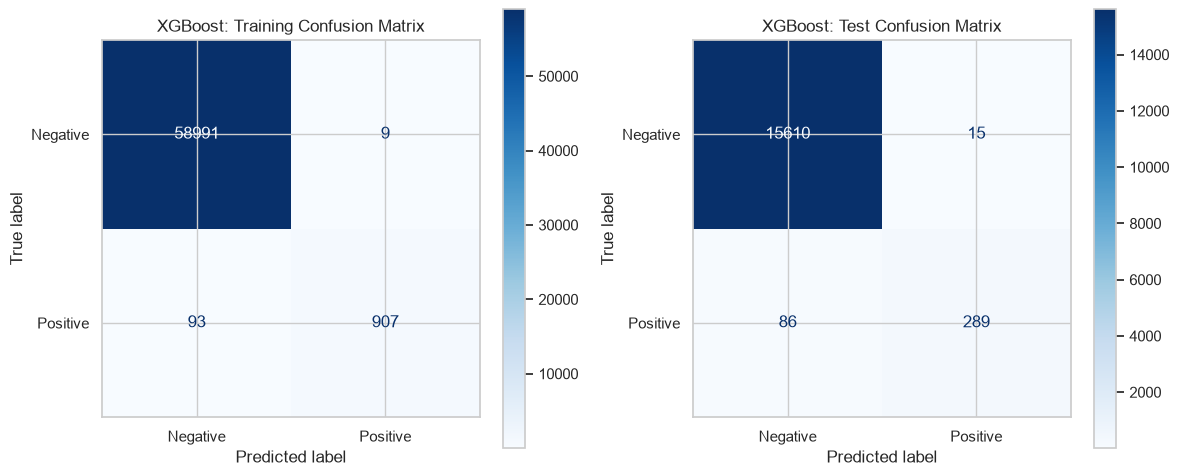

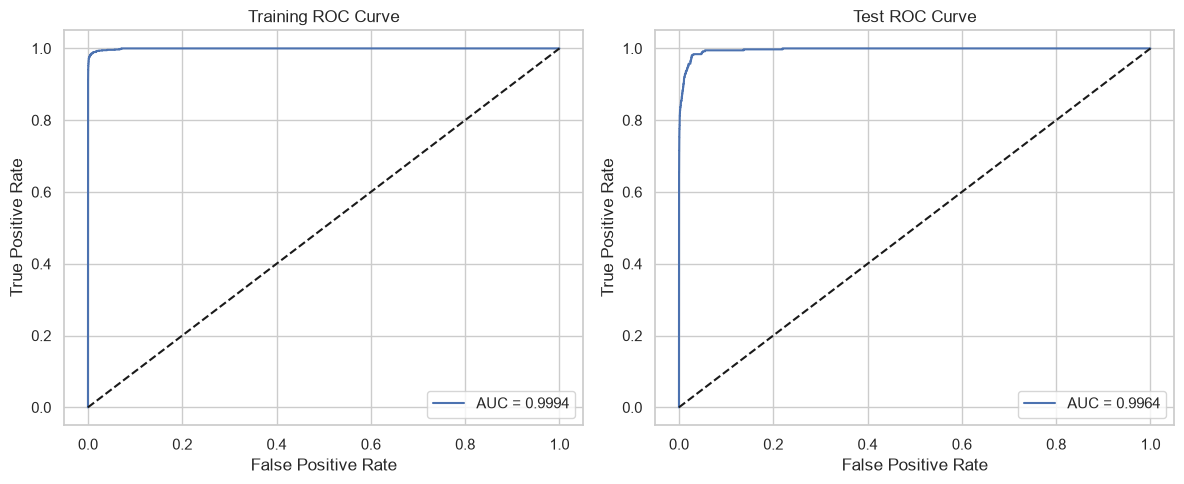

,Metric,Value
0,5-Fold CV Error,0.0059
1,Test Error,0.0063


CV Error: 0.0059
Test Error: 0.0063
Difference (CV - Test): -0.0004


In [12]:
xgb_train_pred = xgb_model.predict(X_train)
xgb_test_pred = xgb_model.predict(X_test)

xgb_train_prob = xgb_model.predict_proba(X_train)[:, 1]
xgb_test_prob = xgb_model.predict_proba(X_test)[:, 1]

xgb_results = pd.DataFrame({
    "Dataset": ["Training", "Test"],
    "AUC": [
        roc_auc_score(y_train, xgb_train_prob),
        roc_auc_score(y_test, xgb_test_prob)
    ],
    "Misclassification Rate": [
        1 - accuracy_score(y_train, xgb_train_pred),
        1 - accuracy_score(y_test, xgb_test_pred)
    ]
})

display(xgb_results.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_train,
    xgb_train_pred,
    display_labels=["Negative", "Positive"],
    cmap="Blues",
    ax=axes[0]
)
axes[0].set_title("XGBoost: Training Confusion Matrix")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    xgb_test_pred,
    display_labels=["Negative", "Positive"],
    cmap="Blues",
    ax=axes[1]
)
axes[1].set_title("XGBoost: Test Confusion Matrix")

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, y_true, y_prob, title in [
    (axes[0], y_train, xgb_train_prob, "Training ROC Curve"),
    (axes[1], y_test, xgb_test_prob, "Test ROC Curve")
]:
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    auc_value = roc_auc_score(y_true, y_prob)

    ax.plot(fpr, tpr, label=f"AUC = {auc_value:.4f}")
    ax.plot([0, 1], [0, 1], "k--")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title(title)
    ax.legend()

plt.tight_layout()
plt.show()

xgb_test_error = 1 - accuracy_score(y_test, xgb_test_pred)

error_comparison = pd.DataFrame({
    "Metric": ["5-Fold CV Error", "Test Error"],
    "Value": [xgb_cv_error, xgb_test_error]
})

display(error_comparison.round(4))

print(f"CV Error: {xgb_cv_error:.4f}")
print(f"Test Error: {xgb_test_error:.4f}")
print(f"Difference (CV - Test): {xgb_cv_error - xgb_test_error:.4f}")

An XGBoost classifier with a binary logistic objective was trained without compensating for class imbalance. L1 regularization was controlled by `reg_alpha`, which penalizes leaf weights in standard gradient-boosted trees rather than fitting separate logistic regression models at each node.

Five-fold stratified cross-validation was used to select α from {0, 0.1, 1, 10}, with median imputation performed within each training fold to prevent data leakage. The optimal α was 0, yielding the lowest mean cross-validation error of 0.0059. Thus, the selected model did not require a nonzero L1 penalty.

The final model achieved a training AUC of 0.9994 and a test AUC of 0.9964, with misclassification rates of 0.0017 and 0.0063, respectively. The training confusion matrix contained 58,991 true negatives, 9 false positives, 93 false negatives, and 907 true positives. The test confusion matrix contained 15,610 true negatives, 15 false positives, 86 false negatives, and 289 true positives.

The five-fold cross-validation error was 0.0059, compared with a test error of 0.0063. The small difference of 0.0004 suggests that cross-validation provided a reasonably accurate estimate of the model's generalization error.

The model correctly identified 289 of the 375 positive test observations, corresponding to a positive-class recall of 77.07%. Compared with the uncompensated Random Forest in part (c), XGBoost achieved a higher test AUC (0.9964 vs. 0.9944), lower misclassification rate (0.0063 vs. 0.0073), and fewer false negatives (86 vs. 101).

Overall, XGBoost demonstrated strong classification performance and outperformed the uncompensated Random Forest on the evaluated test metrics. However, 86 positive observations were still misclassified, indicating that minority-class detection remains an important consideration.

### (f) Use SMOTE to pre-process your data

In [13]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

smote_pipeline = ImbPipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        booster="gbtree",
        tree_method="hist",
        n_estimators=150,
        max_depth=4,
        learning_rate=0.1,
        reg_lambda=1.0,
        scale_pos_weight=1,
        random_state=RANDOM_STATE,
        n_jobs=4
    ))
])

smote_param_grid = {
    "model__reg_alpha": [0, 0.1, 1, 10]
}

smote_search = GridSearchCV(
    estimator=smote_pipeline,
    param_grid=smote_param_grid,
    scoring="accuracy",
    cv=cv,
    n_jobs=1,
    refit=True,
    return_train_score=True
)

print("SMOTE pipeline configured successfully.")

SMOTE pipeline configured successfully.


In [14]:
smote_search.fit(X_train, y_train)

smote_model = smote_search.best_estimator_
smote_best_alpha = smote_search.best_params_["model__reg_alpha"]
smote_cv_error = 1 - smote_search.best_score_

print("Best alpha:", smote_best_alpha)
print(f"5-Fold CV Error: {smote_cv_error:.4f}")

smote_cv_results = pd.DataFrame({
    "Alpha": [
        params["model__reg_alpha"]
        for params in smote_search.cv_results_["params"]
    ],
    "Mean CV Accuracy": smote_search.cv_results_["mean_test_score"],
    "Mean CV Error": 1 - smote_search.cv_results_["mean_test_score"],
    "Std CV Accuracy": smote_search.cv_results_["std_test_score"]
})

display(smote_cv_results.round(4))

Best alpha: 0.1
5-Fold CV Error: 0.0110


,Alpha,Mean CV Accuracy,Mean CV Error,Std CV Accuracy
0,0.0,0.9890,0.0110,0.0014
1,0.1,0.9890,0.0110,0.0010
2,1.0,0.9887,0.0113,0.0011
3,10.0,0.9882,0.0118,0.0008


,Dataset,AUC,Misclassification Rate
0,Training,0.9982,0.0077
1,Test,0.9946,0.0110


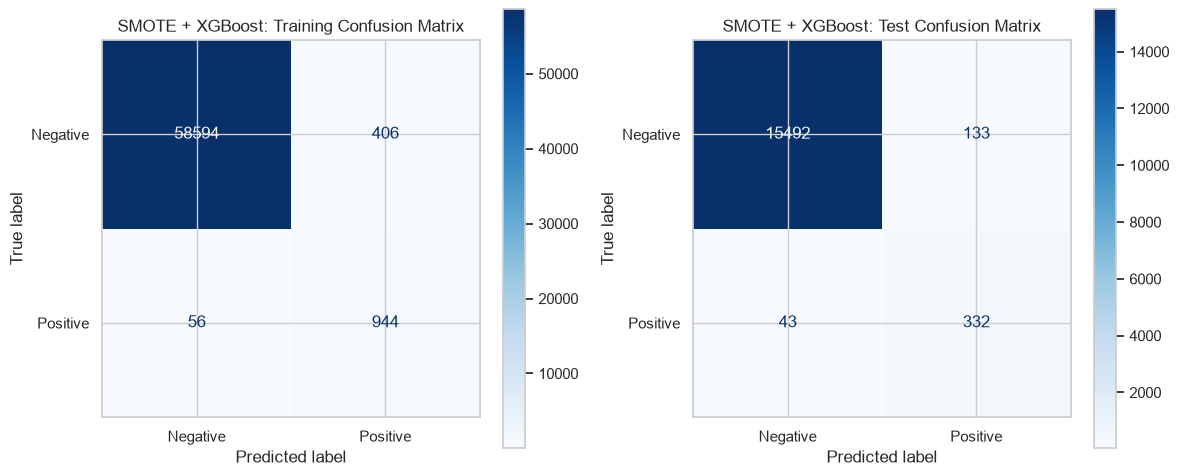

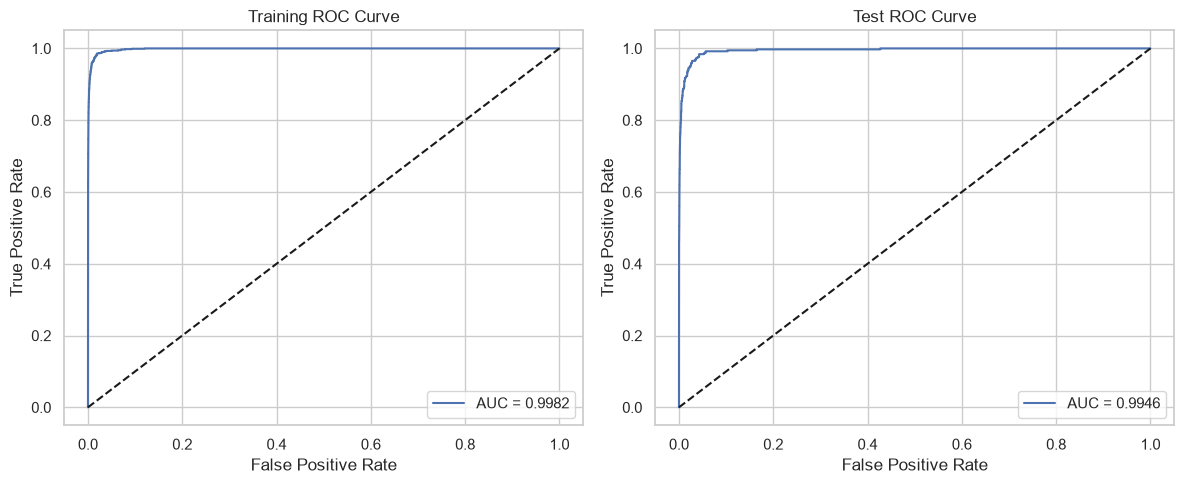

,Metric,Value
0,5-Fold CV Error,0.011
1,Test Error,0.011


CV Error: 0.0110
Test Error: 0.0110
Difference (CV - Test): -0.0000


In [15]:
smote_train_pred = smote_model.predict(X_train)
smote_test_pred = smote_model.predict(X_test)

smote_train_prob = smote_model.predict_proba(X_train)[:, 1]
smote_test_prob = smote_model.predict_proba(X_test)[:, 1]

smote_results = pd.DataFrame({
    "Dataset": ["Training", "Test"],
    "AUC": [
        roc_auc_score(y_train, smote_train_prob),
        roc_auc_score(y_test, smote_test_prob)
    ],
    "Misclassification Rate": [
        1 - accuracy_score(y_train, smote_train_pred),
        1 - accuracy_score(y_test, smote_test_pred)
    ]
})

display(smote_results.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_train,
    smote_train_pred,
    display_labels=["Negative", "Positive"],
    cmap="Blues",
    ax=axes[0]
)
axes[0].set_title("SMOTE + XGBoost: Training Confusion Matrix")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    smote_test_pred,
    display_labels=["Negative", "Positive"],
    cmap="Blues",
    ax=axes[1]
)
axes[1].set_title("SMOTE + XGBoost: Test Confusion Matrix")

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, y_true, y_prob, title in [
    (axes[0], y_train, smote_train_prob, "Training ROC Curve"),
    (axes[1], y_test, smote_test_prob, "Test ROC Curve")
]:
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    auc_value = roc_auc_score(y_true, y_prob)

    ax.plot(fpr, tpr, label=f"AUC = {auc_value:.4f}")
    ax.plot([0, 1], [0, 1], "k--")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title(title)
    ax.legend()

plt.tight_layout()
plt.show()

smote_test_error = 1 - accuracy_score(y_test, smote_test_pred)

error_comparison = pd.DataFrame({
    "Metric": ["5-Fold CV Error", "Test Error"],
    "Value": [smote_cv_error, smote_test_error]
})

display(error_comparison.round(4))

print(f"CV Error: {smote_cv_error:.4f}")
print(f"Test Error: {smote_test_error:.4f}")
print(f"Difference (CV - Test): {smote_cv_error - smote_test_error:.4f}")

In [16]:
xgb_comparison = pd.DataFrame({
    "Metric": [
        "Best Alpha",
        "CV Error",
        "Training AUC",
        "Test AUC",
        "Training Error",
        "Test Error",
        "Test False Positives",
        "Test False Negatives",
        "Test Positive Recall"
    ],
    "XGBoost": [
        xgb_best_alpha,
        xgb_cv_error,
        roc_auc_score(y_train, xgb_train_prob),
        roc_auc_score(y_test, xgb_test_prob),
        1 - accuracy_score(y_train, xgb_train_pred),
        xgb_test_error,
        confusion_matrix(y_test, xgb_test_pred)[0, 1],
        confusion_matrix(y_test, xgb_test_pred)[1, 0],
        confusion_matrix(y_test, xgb_test_pred)[1, 1] / sum(y_test == 1)
    ],
    "SMOTE + XGBoost": [
        smote_best_alpha,
        smote_cv_error,
        roc_auc_score(y_train, smote_train_prob),
        roc_auc_score(y_test, smote_test_prob),
        1 - accuracy_score(y_train, smote_train_pred),
        smote_test_error,
        confusion_matrix(y_test, smote_test_pred)[0, 1],
        confusion_matrix(y_test, smote_test_pred)[1, 0],
        confusion_matrix(y_test, smote_test_pred)[1, 1] / sum(y_test == 1)
    ]
})

display(xgb_comparison.round(4))

,Metric,XGBoost,SMOTE + XGBoost
0,Best Alpha,0.0000,0.1000
1,CV Error,0.0059,0.0110
2,Training AUC,0.9994,0.9982
3,Test AUC,0.9964,0.9946
4,Training Error,0.0017,0.0077
5,Test Error,0.0063,0.0110
6,Test False Positives,15.0000,133.0000
7,Test False Negatives,86.0000,43.0000
8,Test Positive Recall,0.7707,0.8853


SMOTE (Synthetic Minority Over-sampling Technique) was applied to compensate for the severe class imbalance in the APS Failure dataset. SMOTE generates synthetic minority-class observations by interpolating between neighboring minority-class samples.

An imbalanced-learn pipeline was constructed to perform median imputation, SMOTE, and XGBoost training. Five-fold stratified cross-validation was used, with imputation and SMOTE applied only to the training portion of each fold to prevent data leakage. The validation folds retained their original class distributions. The same XGBoost hyperparameters and candidate L1 regularization values as in part (e) were used. The optimal α was 0.1, yielding a mean cross-validation error of approximately 0.0110.

The SMOTE-based model achieved training and test AUC values of 0.9982 and 0.9946, respectively, with misclassification rates of 0.0077 and 0.0110. The training confusion matrix contained 58,594 true negatives, 406 false positives, 56 false negatives, and 944 true positives. The test confusion matrix contained 15,492 true negatives, 133 false positives, 43 false negatives, and 332 true positives.

The five-fold cross-validation error and test error were both approximately 0.0110, indicating close agreement between the estimated and observed misclassification rates.

Compared with XGBoost without SMOTE, the SMOTE-based model reduced false negatives from 86 to 43 and increased positive-class recall from 77.07% to 88.53%. However, false positives increased from 15 to 133, while the test misclassification rate increased from 0.0063 to 0.0110 and test AUC decreased from 0.9964 to 0.9946.

Overall, **XGBoost without SMOTE performed better in terms of overall test error and AUC, whereas SMOTE + XGBoost achieved substantially better minority-class recall**. The preferred model depends on the relative costs of false negatives and false positives. If failing to detect APS failures is particularly costly, the SMOTE-based model may be preferable despite its higher false-positive rate. These results demonstrate the trade-off between minority-class detection and overall classification accuracy.

## 2. ISLR 6.6.3

**(a) iv. Steadily decrease.**

As \(s\) increases, the L1 constraint becomes less restrictive, allowing the model greater flexibility. Because the set of feasible coefficient values expands, the minimum training RSS cannot increase. Therefore, training RSS decreases or remains unchanged as \(s\) increases.

**(b) ii. Decrease initially, and then eventually start increasing in a U shape.**

When \(s\) is small, the model is highly constrained and may underfit the data, resulting in high test RSS. As \(s\) increases, the model becomes more flexible and test RSS initially decreases. However, excessive flexibility may lead to overfitting, causing test RSS to increase again.

**(c) iii. Steadily increase.**

Increasing \(s\) reduces the amount of regularization and increases model flexibility. More flexible models are generally more sensitive to fluctuations in the training data, resulting in higher variance.

**(d) iv. Steadily decrease.**

When \(s\) is small, strong regularization restricts the coefficients and may introduce substantial bias. As \(s\) increases, the constraint is relaxed, allowing the model to fit the underlying relationship more accurately. Therefore, squared bias generally decreases.

**(e) v. Remain constant.**

Irreducible error arises from inherent randomness in the data and cannot be eliminated by changing the model's complexity or regularization strength. Therefore, it remains constant as \(s\) increases.

## 3. ISLR 6.6.5

#### (a) Ridge Regression Optimization Problem

The ridge regression optimization problem is

$$
\min_{\beta_1,\beta_2}
\left\{
\sum_{i=1}^{2}
(y_i-\beta_1x_{i1}-\beta_2x_{i2})^2
+\lambda(\beta_1^2+\beta_2^2)
\right\}.
$$

Since $x_{i1}=x_{i2}=x_i$ and $\hat{\beta}_0=0$, the optimization problem simplifies to

$$
\boxed{
\min_{\beta_1,\beta_2}
\left\{
\sum_{i=1}^{2}
[y_i-x_i(\beta_1+\beta_2)]^2
+\lambda(\beta_1^2+\beta_2^2)
\right\}.
}
$$

#### (b) Equality of Ridge Regression Coefficients

Taking the partial derivatives of the ridge objective with respect to $\beta_1$ and $\beta_2$, we obtain

$$
-2\sum_{i=1}^{2}x_i
[y_i-x_i(\beta_1+\beta_2)]
+2\lambda\beta_1=0
$$

and

$$
-2\sum_{i=1}^{2}x_i
[y_i-x_i(\beta_1+\beta_2)]
+2\lambda\beta_2=0.
$$

Subtracting these two equations gives

$$
2\lambda(\beta_1-\beta_2)=0.
$$

For $\lambda>0$, it follows that

$$
\boxed{\hat{\beta}_1=\hat{\beta}_2.}
$$

Therefore, ridge regression assigns equal coefficients to identical predictors because unequal coefficients would increase the L2 penalty without improving the residual sum of squares.

#### (c) Lasso Optimization Problem

The lasso regression optimization problem is

$$
\min_{\beta_1,\beta_2}
\left\{
\sum_{i=1}^{2}
(y_i-\beta_1x_{i1}-\beta_2x_{i2})^2
+\lambda(|\beta_1|+|\beta_2|)
\right\}.
$$

Since $x_{i1}=x_{i2}=x_i$ and $\hat{\beta}_0=0$, this simplifies to

$$
\boxed{
\min_{\beta_1,\beta_2}
\left\{
\sum_{i=1}^{2}
[y_i-x_i(\beta_1+\beta_2)]^2
+\lambda(|\beta_1|+|\beta_2|)
\right\}.
}
$$

#### (d) Non-Uniqueness of Lasso Coefficients

Let

$$
t=\beta_1+\beta_2.
$$

Since the two predictors are identical, the residual sum of squares depends only on $t$:

$$
RSS=\sum_{i=1}^{2}(y_i-x_it)^2.
$$

By the triangle inequality,

$$
|\beta_1|+|\beta_2|
\geq |\beta_1+\beta_2|=|t|.
$$

Equality holds when $\beta_1$ and $\beta_2$ have the same sign or when either coefficient is zero.

Therefore, for a fixed nonzero optimal sum $\hat{t}$, any pair satisfying

$$
\boxed{
\beta_1+\beta_2=\hat{t},
\qquad
|\beta_1|+|\beta_2|=|\hat{t}|
}
$$

achieves the same minimum objective value.

For example, if $\hat{t}>0$, possible solutions include

$$
(\beta_1,\beta_2)
=(\hat{t},0),
\quad
(0,\hat{t}),
\quad
\left(\frac{\hat{t}}{2},\frac{\hat{t}}{2}\right).
$$

More generally, all solutions can be expressed as

$$
\boxed{
(\beta_1,\beta_2)=(a,\hat{t}-a),
\qquad 0\leq a\leq\hat{t}.
}
$$

If $\hat{t}<0$, the analogous solutions have both coefficients nonpositive. If $\hat{t}=0$ and $\lambda>0$, the unique solution is $(0,0)$.

Thus, whenever the optimal coefficient sum is nonzero, the lasso coefficients are not unique. Unlike ridge regression, lasso does not necessarily distribute coefficients equally among identical predictors and may assign the entire coefficient to only one predictor.


## 4. ISLR 8.4.5

**1. Majority Vote Approach**

Under majority voting, each classification tree predicts Red if $P(\text{Red}\mid X)>0.5$ and Green otherwise.

Among the ten predicted probabilities:

- Four probabilities (0.1, 0.15, 0.2, 0.2) are below 0.5, corresponding to Green.
- Six probabilities (0.55, 0.6, 0.6, 0.65, 0.7, 0.75) are above 0.5, corresponding to Red.

Therefore, the majority vote is

$$
\text{Red votes}=6,\qquad \text{Green votes}=4.
$$

The final classification is

$$
\boxed{\text{Red}}
$$

**2. Average Probability Approach**

Under the average probability approach, we calculate the mean of the ten estimated probabilities:

$$
\begin{aligned}
\bar{P}(\text{Red}\mid X)
&=\frac{1}{10}\sum_{b=1}^{10}\hat{P}_b(\text{Red}\mid X)\\
&=\frac{0.1+0.15+0.2+0.2+0.55+0.6+0.6+0.65+0.7+0.75}{10}\\
&=\frac{4.5}{10}\\
&=0.45.
\end{aligned}
$$

Since

$$
\bar{P}(\text{Red}\mid X)=0.45<0.5,
$$

the final classification is

$$
\boxed{\text{Green}}
$$

**Conclusion**

The majority vote approach predicts **Red**, while the average probability approach predicts **Green**. The two approaches differ because majority voting considers only the class predicted by each tree, whereas averaging probabilities also accounts for the strength of each tree's estimated probability.


## 5. ISLR 9.7.3

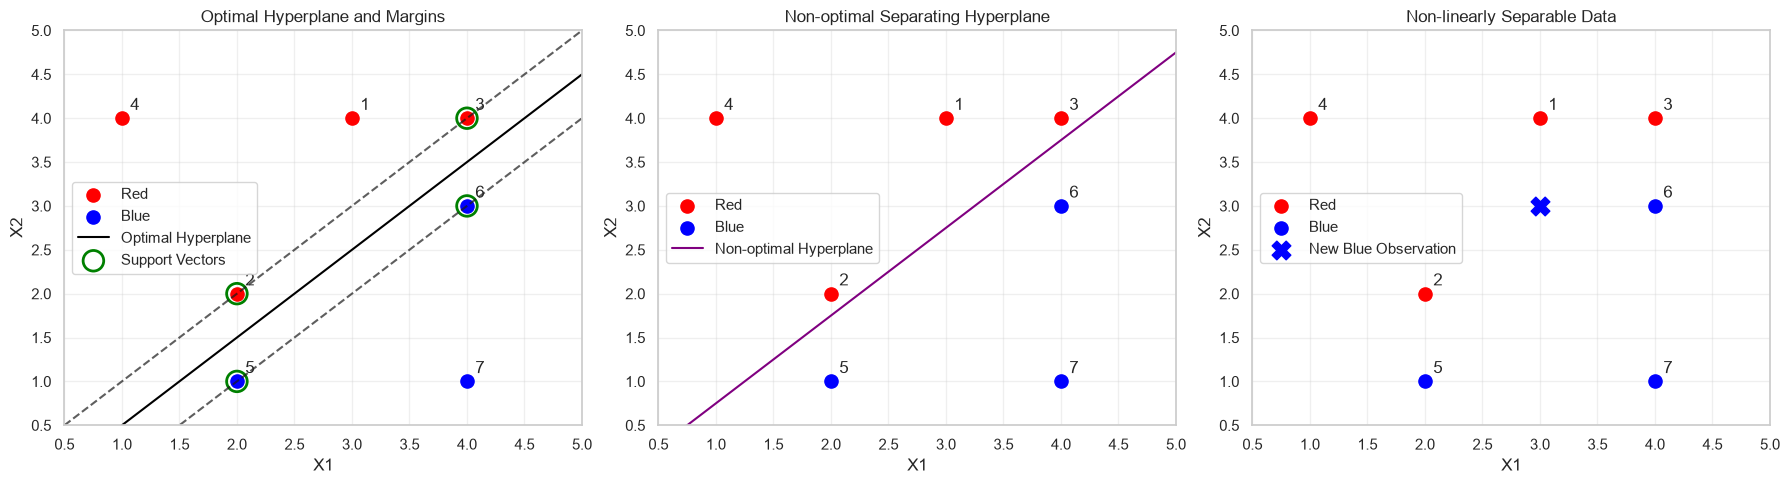

In [17]:

import numpy as np
import matplotlib.pyplot as plt

X = np.array([
    [3, 4],
    [2, 2],
    [4, 4],
    [1, 4],
    [2, 1],
    [4, 3],
    [4, 1]
])

y = np.array([1, 1, 1, 1, -1, -1, -1])

x_line = np.linspace(0.5, 5, 200)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax in axes:
    ax.scatter(
        X[y == 1, 0], X[y == 1, 1],
        color="red", s=90, label="Red"
    )
    ax.scatter(
        X[y == -1, 0], X[y == -1, 1],
        color="blue", s=90, label="Blue"
    )

    for i, (x1, x2) in enumerate(X):
        ax.annotate(
            str(i + 1), (x1, x2),
            xytext=(6, 6),
            textcoords="offset points"
        )

    ax.set_xlim(0.5, 5)
    ax.set_ylim(0.5, 5)
    ax.set_xlabel("X1")
    ax.set_ylabel("X2")
    ax.grid(alpha=0.3)
    ax.legend()

axes[0].plot(
    x_line, x_line - 0.5,
    color="black", label="Optimal Hyperplane"
)
axes[0].plot(
    x_line, x_line,
    "k--", alpha=0.7
)
axes[0].plot(
    x_line, x_line - 1,
    "k--", alpha=0.7
)

support_indices = [1, 2, 4, 5]

axes[0].scatter(
    X[support_indices, 0],
    X[support_indices, 1],
    s=220,
    facecolors="none",
    edgecolors="green",
    linewidths=2,
    label="Support Vectors"
)

axes[0].set_title("Optimal Hyperplane and Margins")
axes[0].legend()

axes[1].plot(
    x_line, x_line - 0.25,
    color="purple",
    label="Non-optimal Hyperplane"
)
axes[1].set_title("Non-optimal Separating Hyperplane")
axes[1].legend()

axes[2].scatter(
    [3], [3],
    color="blue",
    marker="X",
    s=180,
    label="New Blue Observation"
)
axes[2].set_title("Non-linearly Separable Data")
axes[2].legend()

plt.tight_layout()
plt.show()


#### (a) Sketch the Observations

The seven observations are plotted in the figure above, with red and blue points representing the two classes.

The red observations are $(3,4)$, $(2,2)$, $(4,4)$, and $(1,4)$, while the blue observations are $(2,1)$, $(4,3)$, and $(4,1)$.

#### (b) Optimal Separating Hyperplane

The optimal separating hyperplane is

$$
\boxed{X_2=X_1-\frac{1}{2}}
$$

Equivalently, in the form $\beta_0+\beta_1X_1+\beta_2X_2=0$,

$$
\boxed{1-2X_1+2X_2=0}.
$$

This hyperplane lies halfway between the closest parallel boundaries containing observations from the two classes, thereby maximizing the separation margin.

#### (c) Classification Rule

The maximal margin classifier uses the following decision function:

$$
f(X)=1-2X_1+2X_2.
$$

The classification rule is

$$
\boxed{
\hat{Y}=
\begin{cases}
\text{Red}, & 1-2X_1+2X_2>0,\\
\text{Blue}, & 1-2X_1+2X_2<0.
\end{cases}
}
$$

Thus, the coefficients are

$$
\boxed{\beta_0=1,\quad\beta_1=-2,\quad\beta_2=2}.
$$

Points exactly on the decision boundary require a tie-breaking convention.

#### (d) Margin of the Maximal Margin Hyperplane

The two margin boundaries are

$$
X_2=X_1
$$

and

$$
X_2=X_1-1.
$$

The optimal separating hyperplane lies exactly halfway between these two parallel lines.

The perpendicular distance from the separating hyperplane to either margin boundary is

$$
M=\frac{1}{\sqrt{(-2)^2+2^2}}
=\frac{1}{2\sqrt{2}}
\approx 0.3536.
$$

Therefore, the total width between the two margin boundaries is

$$
\boxed{2M=\frac{1}{\sqrt{2}}\approx 0.7071}.
$$

The dashed lines in the first plot represent the margin boundaries.

#### (e) Support Vectors

The support vectors are the observations located exactly on the margin boundaries:

$$
\boxed{
\begin{aligned}
&\text{Observation 2: }(2,2),\quad \text{Red},\\
&\text{Observation 3: }(4,4),\quad \text{Red},\\
&\text{Observation 5: }(2,1),\quad \text{Blue},\\
&\text{Observation 6: }(4,3),\quad \text{Blue}.
\end{aligned}
}
$$

These four observations determine the position and orientation of the maximal margin hyperplane.

#### (f) Movement of the Seventh Observation

The seventh observation, $(4,1)$, is not a support vector because it lies farther from the separating hyperplane than the margin boundaries.

Since the maximal margin hyperplane is determined by the support vectors, a small movement of the seventh observation will not change the optimal hyperplane, provided that it does not become a support vector or violate the existing margin.

#### (g) Non-optimal Separating Hyperplane

An example of a separating hyperplane that is not optimal is

$$
\boxed{X_2=X_1-\frac{1}{4}}.
$$

Equivalently,

$$
\boxed{1-4X_1+4X_2=0}.
$$

This line correctly separates all the red observations from the blue observations. However, it lies closer to the red class than to the blue class, resulting in a smaller minimum margin than the optimal hyperplane.

Therefore, it is a valid separating hyperplane but not the maximal margin hyperplane.

#### (h) Additional Observation Making the Data Non-separable

Consider adding a new blue observation at

$$
\boxed{(X_1,X_2)=(3,3),\quad Y=\text{Blue}}.
$$

This point lies on the line segment connecting the two red observations $(2,2)$ and $(4,4)$:

$$
(3,3)=\frac{1}{2}(2,2)+\frac{1}{2}(4,4).
$$

Therefore, the new blue observation lies within the convex hull of the red class.

A linear classifier cannot place both red endpoints on one side of a hyperplane while placing their midpoint strictly on the other side.

Consequently, the two classes are no longer linearly separable after adding this observation.
